# 🤖 Multi-Agent Workflow: The Employee Assistant

**Welcome!**
In notebook 1 we built a graph **manually** (nodes, edges, state). In notebook 2 we used **`create_agent`** to get a pre-assembled agent. Now we combine both ideas to build a **multi-agent workflow**.

### The Use Case
One "Employee Assistant" front door that handles two very different requests:
1. **Time-off requests** → handled by the agent we built in notebook 2 (reused as-is)
2. **Expense reimbursements** → a new agent that checks company policy documents (light RAG) before submitting a claim

### Architecture: The Router Pattern

```text
                        ┌──────────────────────┐
         User message ─▶│   Intent Classifier   │  (LLM + structured output)
                        └──────────┬───────────┘
                                   │ conditional edge on state["intent"]
               ┌───────────────────┼───────────────────────┐
               ▼                   ▼                       ▼
    ┌──────────────────┐ ┌──────────────────┐   ┌──────────────────┐
    │  Time-Off Agent   │ │  Expense Agent    │   │  Fallback         │
    │  (create_agent,   │ │  (create_agent,   │   │  (plain node,     │
    │   from notebook 2)│ │   policy RAG)     │   │   "I can't help") │
    └──────────────────┘ └──────────────────┘   └──────────────────┘
               └───────────────────┴───────────────────────┘
                                   ▼
                                  END
```

There are two common multi-agent patterns:
* **Router** *(what we build)*: a cheap classifier picks a branch up-front, and exactly **one** specialist agent handles the request. Predictable, fast, easy to debug.
* **Supervisor**: an LLM "manager" agent dynamically delegates to worker agents and can loop between them. More flexible, but harder to control.

### 💡 The Key Insight
`create_agent` returns a **compiled LangGraph**. And a compiled graph can be added to another `StateGraph` **as if it were a plain node**. So multi-agent composition is just:

> build the agents → drop them into a parent graph as nodes → wire the edges.

### 📚 What We Will Cover
1. **Intent classification** with structured output (Pydantic + `with_structured_output`)
2. **Reusing** the time-off agent from notebook 2
3. **Building** an expense agent with light RAG over policy documents
4. **Composing** everything into one parent `StateGraph`
5. **End-to-end demos** — including interrupt/resume flowing *through* the parent graph

![Diagram](./images/13_img.png)

In [1]:
from typing import Literal
from datetime import datetime
from pathlib import Path

from pydantic import BaseModel, Field
from dotenv import load_dotenv

from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_core.documents import Document
from langchain_core.messages import AIMessage
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings

from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command, interrupt

from langraph_prompts import ACTION_PROMPT_TEMPLATE

load_dotenv(override=True)  # .env values take precedence over existing shell env vars

llm = init_chat_model(model="gpt-4o", temperature=0)

## 1) The Intent Classifier

The front door of our assistant. Before any agent runs, we need to decide **which** agent should handle the request.

We don't need a full agent for this — just a single LLM call that returns a **structured answer**. This is a common pattern: use cheap, constrained LLM calls for routing decisions, and save the agent loops for the actual work.

### Code Context
In the code below:
* `IntentClassification`: A Pydantic model. The `Literal[...]` type **forces** the LLM to pick one of exactly three values — it cannot invent a new intent.
* `llm.with_structured_output(...)`: Wraps the model so its response is parsed and validated against the schema. We get a Python object back, not free text.
* We include an `"other"` intent so off-topic requests get a graceful answer instead of being shoehorned into the wrong branch.

📚 **[Docs: Structured output](https://docs.langchain.com/oss/python/langchain/structured-output)**

![Diagram](./images/14_img.png)

In [2]:
CLASSIFIER_PROMPT = """
You are an intent classifier for an employee assistant.
Classify the employee's message into exactly one intent:

- 'time_off': requests about vacation, leave, PTO, sick days, or time-off balances
- 'expense_reimbursement': requests about expensing purchases, reimbursement claims, or expense policy questions
- 'other': anything that does not fit the two intents above
"""


class IntentClassification(BaseModel):
    """Classification of an employee request."""

    intent: Literal["time_off", "expense_reimbursement", "other"] = Field(
        description="The single best-matching intent for the user's message"
    )
    reasoning: str = Field(
        description="One short sentence explaining why this intent was chosen"
    )


intent_classifier = llm.with_structured_output(IntentClassification)

### 1.1) Testing the classifier in isolation

Before wiring anything together, let's make sure the classifier behaves — one message per intent.

In [3]:
test_messages = [
    "I want to take next Friday off",
    "Can I expense a $300 client dinner?",
    "What's the wifi password in the Austin office?",
]

for msg in test_messages:
    result = intent_classifier.invoke(
        [
            {"role": "system", "content": CLASSIFIER_PROMPT},
            {"role": "user", "content": msg},
        ]
    )
    print(f"{msg!r:55} -> {result.intent:22} | {result.reasoning}")

'I want to take next Friday off'                        -> time_off               | The message is about taking a day off, which relates to time-off requests.
'Can I expense a $300 client dinner?'                   -> expense_reimbursement  | The message is asking about expensing a purchase, which falls under expense reimbursement.
"What's the wifi password in the Austin office?"        -> other                  | The question is about office facilities, not time off or expenses.


## 2) Specialist #1: The Time-Off Agent

This is **exactly the agent from notebook 2** — same tools, same prompt. We're reusing it untouched, which is the whole point: a well-built agent is a component you can compose.

### ⚠️ One important difference: no checkpointer here
In notebook 2 we passed `checkpointer=InMemorySaver()` to `create_agent`. Here we **don't**. When a compiled graph runs as a node inside a parent graph, **the parent's checkpointer is automatically propagated to it**. The parent owns persistence; the sub-agents inherit it.

![Diagram](./images/15_img.png)

In [4]:
@tool
def get_time_off_balance(user_id: str) -> int:
    """
    Get the time off balance for a user.

    Args:
        user_id: A unique string representing the user id

    Returns:
        An integer value representing the time-off balance
    """
    return 10


@tool
def process_time_off(user_id: str, start_date: str, end_date: str) -> dict:
    """
    Process time-off request for a user

    Args:
        user_id: A unique string representing the user id
        start_date: A date string in YYYY-MM-DD format for the start date of the time-off request
        end_date: A date string in YYYY-MM-DD format for the end date of the time-off request

    Returns:
        A dictionary with the following keys:
        - status: A string value representing the status of the time-off request
        - message: A string value representing the message of the time-off request
    """
    start_date = datetime.strptime(start_date, "%Y-%m-%d")
    end_date = datetime.strptime(end_date, "%Y-%m-%d")

    days_requested = end_date - start_date
    time_off_balance = get_time_off_balance.invoke({"user_id": user_id})

    result = {}

    if days_requested.days + 1 > time_off_balance:
        result["status"] = "error"
        result["message"] = f"Time off request failed. you only have {time_off_balance} days of remaining leaves but requested {days_requested.days} days"
    else:
        time_off_balance -= days_requested.days + 1
        result["status"] = "success"
        result["message"] = f"Time off request processed successfully for {days_requested.days + 1} days. Your remaining time off balance is {time_off_balance}"

    return result


@tool
def get_additional_info_from_human(message: str) -> str:
    """
    Raises an interrupt to fetch additional information from the human requesting the action

    Args:
        message: a message string from the AI requesting the user for missing information

    Returns:
        A string value representing the response with additional information from the human
    """
    interrupt_result = interrupt(message)

    return interrupt_result["user_message"]

In [5]:
user_id = "1"
todays_date = datetime.now().strftime("%Y-%m-%d")

time_off_system_prompt = ACTION_PROMPT_TEMPLATE.format(todays_date=todays_date, user_id=user_id)

time_off_agent = create_agent(
    llm,
    tools=[get_time_off_balance, process_time_off, get_additional_info_from_human],
    system_prompt=time_off_system_prompt,
)

## 3) Company Policy Documents (Light RAG)

The expense agent needs to know **company policy**: how much can you spend on a client dinner? Do you need a receipt?

In a real company these policies live in long PDF handbooks — far too big to paste into a system prompt. The standard solution is **RAG (Retrieval Augmented Generation)**:

1. **Index**: embed each policy document into a vector store (once, up-front)
2. **Retrieve**: at question time, embed the query and find the most similar documents
3. **Generate**: the agent answers using only the retrieved excerpts

We'll generate three small sample policy files so the demo is fully self-contained.

![Diagram](./images/16_img.png)

In [6]:
POLICIES = {
    "travel": """# Travel & Lodging Policy

- Flights must be booked in economy class for trips under 6 hours.
- Hotel stays are reimbursed up to $250 per night.
- Flights and hotels should be booked at least 14 days in advance when possible.
- Ground transportation (taxi, rideshare, public transit) is fully reimbursable with receipts.
- Personal car mileage is reimbursed at $0.65 per mile.
""",
    "meals": """# Meals & Entertainment Policy

- Client meals are reimbursed up to $75 per person, including tax and tip.
- Meals during solo business travel are reimbursed up to $25 per day.
- An itemized receipt is required for any meal expense over $25.
- Alcohol is not reimbursable under any circumstances.
- The names of all attendees must be listed for client meals.
""",
    "equipment": """# Equipment & Home Office Policy

- Laptops are refreshed every 3 years with a budget of up to $1,500.
- Peripherals (keyboard, mouse, headset) are reimbursed up to $200 per calendar year.
- Monitors are reimbursed up to $300, once every 3 years.
- Any purchase above these limits requires written manager approval BEFORE purchase.
- All equipment purchased with company funds remains company property.
""",
}

policy_dir = Path("policies")
policy_dir.mkdir(exist_ok=True)

for category, content in POLICIES.items():
    (policy_dir / f"{category}.md").write_text(content)

print(f"Wrote {len(POLICIES)} policy files to {policy_dir.resolve()}")

Wrote 3 policy files to /Users/arvindna/Desktop/Maven Demos/Week3/Session1/langgraph/policies


### 3.1) Indexing the policies into a vector store

### Code Context
In the code below:
* `Document`: LangChain's container for a piece of text + metadata. We tag each doc with its category.
* `OpenAIEmbeddings`: turns text into vectors so "client dinner" can match the *meals* policy even though the words differ.
* `InMemoryVectorStore`: the simplest possible vector store — perfect for a demo. In production you'd use Chroma, FAISS, Pinecone, etc.
* Our documents are tiny, so we skip chunking. With real handbooks you'd split them first with a text splitter.

📚 **[Docs: Retrieval](https://docs.langchain.com/oss/python/langchain/retrieval)**

In [8]:
policy_dir = Path("policies")
policy_dir.mkdir(exist_ok=True)

policy_docs = [
    Document(
        page_content=path.read_text(),
        metadata={"category": path.stem},
    )
    for path in sorted(policy_dir.glob("*.md"))
]

embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
vectorstore = InMemoryVectorStore.from_documents(policy_docs, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 1})

# Sanity check: a question about dinner should surface the MEALS policy
hits = retriever.invoke("How much can I spend on a client dinner?")
print(hits[0].metadata, "\n")
print(hits[0].page_content)

{'category': 'meals'} 

# Meals & Entertainment Policy

- Client meals are reimbursed up to $75 per person, including tax and tip.
- Meals during solo business travel are reimbursed up to $25 per day.
- An itemized receipt is required for any meal expense over $25.
- Alcohol is not reimbursable under any circumstances.
- The names of all attendees must be listed for client meals.



## 4) Specialist #2: The Expense Reimbursement Agent

Same recipe as the time-off agent — `create_agent` + tools — but with two new tools:

* `search_expense_policy`: wraps our retriever. Searching the policy is now **just another tool** the agent can decide to call. This is "agentic RAG" in its simplest form.
* `submit_expense`: a mock claims system. Amounts within the auto-approval limit are approved instantly; anything above is routed to a manager.

We also reuse `get_additional_info_from_human`, so this agent can pause and ask for missing details (amount, category, ...) exactly like the time-off agent does.

![Diagram](./images/17_img.png)

In [9]:
AUTO_APPROVE_LIMITS = {"meals": 150, "travel": 500, "equipment": 200}


@tool
def search_expense_policy(query: str) -> str:
    """
    Search the company expense policy documents for rules relevant to a query.

    Args:
        query: A natural language question about expense policy

    Returns:
        The most relevant policy document text
    """
    docs = retriever.invoke(query)
    return "\n\n".join(f"[policy: {d.metadata['category']}]\n{d.page_content}" for d in docs)


@tool
def submit_expense(user_id: str, amount: float, category: str, description: str) -> dict:
    """
    Submit an expense reimbursement claim for a user.

    Args:
        user_id: A unique string representing the user id
        amount: The total expense amount in USD
        category: The expense category. One of: 'meals', 'travel', 'equipment'
        description: A short description of the expense

    Returns:
        A dictionary with the following keys:
        - status: 'approved' or 'pending_review'
        - claim_id: A unique id for the submitted claim
        - message: A human-readable summary of the outcome
    """
    limit = AUTO_APPROVE_LIMITS.get(category, 100)
    claim_id = f"EXP-{abs(hash((user_id, amount, description))) % 10000:04d}"

    if amount <= limit:
        return {
            "status": "approved",
            "claim_id": claim_id,
            "message": f"Expense of ${amount:.2f} ({category}) auto-approved. Reimbursement will be included in the next payroll cycle.",
        }

    return {
        "status": "pending_review",
        "claim_id": claim_id,
        "message": f"Expense of ${amount:.2f} ({category}) exceeds the ${limit} auto-approval limit and has been routed to your manager for review.",
    }

In [10]:
EXPENSE_PROMPT_TEMPLATE = """
You are a helpful and accurate employee Expense Reimbursement Assistant.
You are given a user's request, and you need to reason about it and call the necessary tools to handle it.

Follow these rules:
1. ALWAYS search the expense policy first to check whether the expense is within policy.
2. If information needed to submit a claim is missing (amount, category, or description), ask the human for it.
3. Once you have the amount, category, and description, submit the claim immediately — do NOT ask for confirmation.
4. After submitting, clearly tell the user whether the expense was within policy and what the outcome was.
5. Valid categories are: meals, travel, equipment.

today's date : {todays_date}

user_id : {user_id}
"""

expense_system_prompt = EXPENSE_PROMPT_TEMPLATE.format(todays_date=todays_date, user_id=user_id)

expense_agent = create_agent(
    llm,
    tools=[search_expense_policy, submit_expense, get_additional_info_from_human],
    system_prompt=expense_system_prompt,
)

## 5) Composing the Parent Graph

Now the payoff. We assemble everything into one `StateGraph`:

* **State**: `MessagesState` (the shared conversation) + an `intent` field. Both sub-agents also use a `messages` key internally, so state flows in and out of them with **zero glue code**.
* **`classify_intent` node**: runs our structured-output classifier and writes `intent` into state.
* **Conditional edge**: reads `state["intent"]` and routes to the matching branch.
* **Agent nodes**: `time_off_agent` and `expense_agent` are compiled graphs — we pass them to `add_node` directly, exactly like a plain function.
* **`fallback` node**: a plain Python function for the `"other"` intent. No LLM needed — a node is just a function.
* **Checkpointer**: passed once, at the parent `compile()`. It propagates into the sub-agents, which is what lets interrupt/resume work across the whole system.

📚 **[Docs: Subgraphs](https://docs.langchain.com/oss/python/langgraph/use-subgraphs)**

![Diagram](./images/18_img.png)

In [11]:
class AssistantState(MessagesState):
    intent: str


def classify_intent(state: AssistantState) -> dict:
    user_message = state["messages"][-1].content

    result = intent_classifier.invoke(
        [
            {"role": "system", "content": CLASSIFIER_PROMPT},
            {"role": "user", "content": user_message},
        ]
    )

    return {"intent": result.intent}


def route_intent(state: AssistantState) -> Literal["time_off_agent", "expense_agent", "fallback"]:
    if state["intent"] == "time_off":
        return "time_off_agent"
    if state["intent"] == "expense_reimbursement":
        return "expense_agent"
    return "fallback"


def fallback(state: AssistantState) -> dict:
    return {
        "messages": [
            AIMessage(
                content=(
                    "Sorry, I can only help with time-off requests and expense reimbursements. "
                    "Try asking me something like 'I want to take Friday off' "
                    "or 'Can I expense a new keyboard?'"
                )
            )
        ]
    }


workflow = (
    StateGraph(AssistantState)
    .add_node("classify_intent", classify_intent)
    .add_node("time_off_agent", time_off_agent)
    .add_node("expense_agent", expense_agent)
    .add_node("fallback", fallback)
    .add_edge(START, "classify_intent")
    .add_conditional_edges(
        "classify_intent",
        route_intent,
        ["time_off_agent", "expense_agent", "fallback"],
    )
    .add_edge("time_off_agent", END)
    .add_edge("expense_agent", END)
    .add_edge("fallback", END)
)

assistant = workflow.compile(checkpointer=InMemorySaver())

### 5.1) Visualizing the architecture

`xray=True` looks **inside** the sub-agents: you can see the model→tools loop that `create_agent` built for us, now embedded in our router.

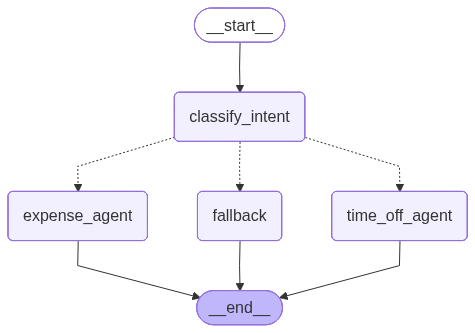

In [12]:
from IPython.display import Image

Image(assistant.get_graph().draw_mermaid_png())

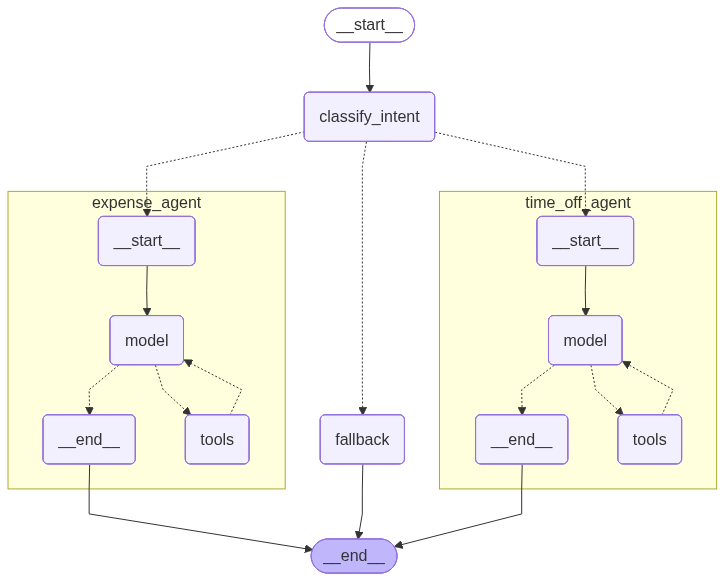

In [13]:
Image(assistant.get_graph(xray=True).draw_mermaid_png())

## 6) End-to-End Demos

A tiny helper so we can focus on the conversation instead of raw state dumps.

In [14]:
def show(result):
    """Print the assistant's reply, or the question it paused on."""
    if "__interrupt__" in result:
        print("⏸️  INTERRUPTED — the assistant is asking:")
        print("   ", result["__interrupt__"][0].value)
    else:
        print("🤖", result["messages"][-1].content)

### 6.1) Demo: Time-off request (with interrupt/resume)

The request is missing dates, so the time-off agent pauses with an interrupt. Note that the interrupt is raised **deep inside a sub-agent**, yet it surfaces cleanly through the parent graph — and we resume at the parent too. The checkpointer makes the whole composed system pausable.

In [15]:
config = {"configurable": {"thread_id": "demo-time-off"}}

result = assistant.invoke(
    {"messages": [{"role": "user", "content": "I want to take some leave"}]},
    config=config,
)
show(result)

⏸️  INTERRUPTED — the assistant is asking:
    Could you please provide the start and end dates for your leave request?


In [16]:
result = assistant.invoke(Command(resume={"user_message": "tomorrow"}), config=config)
show(result)

🤖 Your time-off request for tomorrow has been processed successfully for 1 day. Your remaining time-off balance is 9 days.


### 6.2) Demo: Expense reimbursement

A $300 dinner for 2 clients. Watch the agent: it searches the policy (finds the $75/person meals cap), realizes the claim is over the auto-approval limit, and the mock claims system routes it to a manager.

In [17]:
config = {"configurable": {"thread_id": "demo-expense"}}

result = assistant.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": (
                    "I'd like to submit a $300 expense for a client dinner. "
                    "I took Maya Chen and Raj Patel from Acme Corp to dinner yesterday "
                    "to discuss the contract renewal."
                ),
            }
        ]
    },
    config=config,
)
show(result)

🤖 The expense for the client dinner was submitted successfully. However, the expense of $300 exceeds the policy limit of $75 per person for client meals, which would total $150 for two guests. Therefore, the claim has been routed to your manager for review and is currently pending approval. The claim ID is EXP-8192.


Let's look under the hood at the full message trace — you can see the routing, the policy search, and the submission as individual steps.

In [18]:
for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

I'd like to submit a $300 expense for a client dinner. I took Maya Chen and Raj Patel from Acme Corp to dinner yesterday to discuss the contract renewal.
================================== Ai Message ==================================
Tool Calls:
  search_expense_policy (call_s8EFBU3gtAXWX98ZgldRhZhy)
 Call ID: call_s8EFBU3gtAXWX98ZgldRhZhy
  Args:
    query: maximum allowable amount for meals expense
================================= Tool Message =================================
Name: search_expense_policy

[policy: meals]
# Meals & Entertainment Policy

- Client meals are reimbursed up to $75 per person, including tax and tip.
- Meals during solo business travel are reimbursed up to $25 per day.
- An itemized receipt is required for any meal expense over $25.
- Alcohol is not reimbursable under any circumstances.
- The names of all attendees must be listed for client meals.

===========================

### 6.3) Demo: Off-topic request → fallback

No agent runs at all here. The classifier returns `"other"`, and the router sends the request straight to our plain-Python fallback node. Cheap, fast, and it never hallucinates an answer about wifi passwords.

In [19]:
config = {"configurable": {"thread_id": "demo-other"}}

result = assistant.invoke(
    {"messages": [{"role": "user", "content": "What's the weather like today?"}]},
    config=config,
)
show(result)

🤖 Sorry, I can only help with time-off requests and expense reimbursements. Try asking me something like 'I want to take Friday off' or 'Can I expense a new keyboard?'


## 🎓 Wrap-Up

**What we built:** a router-pattern multi-agent system where every piece is something you already knew:

| Component | Built with | Notebook where you learned it |
|---|---|---|
| Intent classifier | `with_structured_output` + conditional edges | This one |
| Time-off agent | `create_agent` + tools + interrupts | Notebook 2 |
| Expense agent | `create_agent` + a retriever tool (light RAG) | This one |
| Parent graph | `StateGraph` + nodes + edges | Notebook 1 |

**The composition rules to remember:**
1. A compiled graph (including anything from `create_agent`) can be added to a parent graph with `add_node` — sub-agents are just nodes.
2. Sub-graphs share state through common keys (here: `messages`).
3. Pass the checkpointer **once**, at the parent — it propagates down, and interrupts bubble up.

**Where to go from here:**
* Swap the router for a **supervisor** agent that can delegate *and loop* between specialists.
* Give the expense agent `HumanInTheLoopMiddleware` (notebook 2, section 2) so a manager approves `submit_expense` interactively.
* Replace `InMemoryVectorStore` with a persistent store (Chroma/FAISS) and real policy PDFs.